# The Wanli era (1573–1620) and the Chinese territory around it
A use case on one reign: who was active in China under the Wanli Emperor, what their biographies look like, and what happens to the people of the same territory across the Ming–Qing transition.

The **territory** is made of the polities that ruled the land of the Ming (1600 borders) between 1550 and 1720: Ming, Later Jin, Li Zicheng (Shun), Southern Ming and Qing. Everything is read from `cultura_enriched_v3.2`. Each individual has a polity for each stage of life (pre-active, active, post-active life). An individual belongs to the territory when one of these polities is in it. The Wanli set keeps those whose active life overlaps 1573–1620 and is spent in the territory.

In [1]:
import json
import random
import tempfile

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from matplotlib.patches import Patch
from shapely.geometry import shape
from style import *

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
COUNTRIES_PATH = '../../data/ne_110m_admin_0_countries.geojson'

MING = 'Ming Dynasty'
QING = 'Qing Dynasty'
SHORT_NAMES = {MING: 'Ming', 'Later Jin Dynasty': 'Later Jin', 'Li Zicheng': 'Shun', 'Southern Ming': 'Southern Ming', QING: 'Qing'}
TERRITORY_POLITIES = list(SHORT_NAMES)
TOP_PATHS = 12
TERRITORY_WINDOW = (1550, 1720)
REFERENCE_YEAR = 1600
WANLI_START, WANLI_END = 1573, 1620
SERIES_START, SERIES_END = 1520, 1680
TERRITORY_START, TERRITORY_END = 1500, 1720
BIRTH_DECADES = (1500, 1700)
FEMALE_QID = 'Q6581072'
TOP_TIMELINE = 40
TOP_OCCUPATIONS = 15
TOP_BIOGRAPHIES = 30

GENERIC_OCCUPATION = 'politician'
TOP_GROUPS = 7
OCCUPATION_PALETTE = [ORANGE, BLUE, GREEN, PURPLE, RED, TEAL, PINK]
OTHER_OCCUPATION, NO_OCCUPATION = 'other occupation', 'no occupation'

TRANSITION = 'Later Jin, Shun, Southern Ming'
POLITY_GROUP_ORDER = ['Ming', 'Ming and Qing', TRANSITION, 'Qing']
POLITY_GROUP_COLORS = {'Ming': BLUE, 'Ming and Qing': GREEN, TRANSITION: PURPLE, 'Qing': ORANGE}
SOURCE_COLORS = {'CBDB': LIGHT_BLUE, 'other sources': ORANGE}

WANLI_SHADE = {'color': PALE_BLUE, 'alpha': 0.6, 'lw': 0}
MAP_EXTENT = (95, 128, 17, 45)

apply_style()

## External data
Country outlines (Natural Earth, 1:110m) for the map background. The Wanli reign dates (1573–1620) are the only constants not read from the database.

## Load data
### Which polities make the territory
Every Cliopatria territory between 1550 and 1720 that overlaps the Ming borders of 1600.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")

territories = con.sql('''
    SELECT polity.name AS polity, territory.start_year, territory.end_year, territory.geometry
    FROM   polity, unnest(polity.territories) AS unnested(territory)
    WHERE  territory.end_year >= $from_year AND territory.start_year <= $to_year AND territory.geometry IS NOT NULL
''', params={'from_year': TERRITORY_WINDOW[0], 'to_year': TERRITORY_WINDOW[1]}).pl()

shapes = [shape(json.loads(text)).buffer(0) for text in territories['geometry']]
ming_row = territories.with_row_index().filter(
    (pl.col('polity') == MING) & (pl.col('start_year') <= REFERENCE_YEAR) & (pl.col('end_year') >= REFERENCE_YEAR)
)
assert ming_row.height == 1
ming_1600 = shapes[ming_row['index'][0]]

overlap = (
    territories.drop('geometry')
    .with_columns(
        pl.Series('share_inside_ming_1600', [geometry.intersection(ming_1600).area / geometry.area for geometry in shapes]),
        pl.Series('share_of_ming_1600_covered', [geometry.intersection(ming_1600).area / ming_1600.area for geometry in shapes]),
    )
    .group_by('polity')
    .agg(pl.col('start_year').min(), pl.col('end_year').max(),
         pl.col('share_inside_ming_1600').max().round(3), pl.col('share_of_ming_1600_covered').max().round(3))
    .filter(pl.col('share_of_ming_1600_covered') > 0.001)
    .with_columns(pl.col('polity').is_in(TERRITORY_POLITIES).alias('kept'))
    .sort('share_of_ming_1600_covered', descending=True)
)
assert set(TERRITORY_POLITIES) <= set(overlap['polity'])
ming_end = territories.filter(pl.col('polity') == MING)['end_year'].max()
print('end of the Ming in Cliopatria:', ming_end)
overlap

end of the Ming in Cliopatria: 1644


polity,start_year,end_year,share_inside_ming_1600,share_of_ming_1600_covered,kept
str,i64,i64,f64,f64,bool
"""Ming Dynasty""",1547,1644,1.0,1.0,true
"""Allegiance of Joseon to Ming D…",1547,1571,0.935,0.972,false
"""Qing Dynasty""",1645,1720,0.571,0.972,true
"""Southern Ming""",1645,1682,1.0,0.545,true
"""Li Zicheng""",1632,1644,1.0,0.112,true
"""First Toungoo Empire""",1547,1733,0.283,0.045,false
"""Shan States""",1547,1563,0.409,0.027,false
"""Later Jin Dynasty""",1619,1644,0.415,0.023,true


The five kept polities are the regimes that ruled China proper. Left out: "Allegiance of Joseon to Ming Dynasty" (a Cliopatria union that repeats the Ming territory with Korea added) and the Burmese and Shan states, which mostly lie outside it. The Qing territory also covers Mongolia, Tibet and Xinjiang, so "Qing" individuals are not all from China proper.

### Individuals of the territory

In [3]:
con.sql('''
    CREATE TEMP TABLE territory_individuals AS
    SELECT entity.qid AS qid,
           list_transform(pre_active_life_polity,  stage_match -> stage_match.polity.name) AS pre_active_polities,
           list_transform(active_life_polity,      stage_match -> stage_match.polity.name) AS active_polities,
           list_transform(post_active_life_polity, stage_match -> stage_match.polity.name) AS post_active_polities,
           birth_date.year                   AS birth_year,
           death_date.year                   AS death_year,
           start_of_active_life.year         AS active_start,
           end_of_active_life.year           AS active_end,
           entity.description ILIKE '%CBDB%' AS is_cbdb
    FROM   individual_enriched
    WHERE  list_has_any(list_transform(pre_active_life_polity || active_life_polity || post_active_life_polity,
                                       stage_match -> stage_match.polity.name), $names)
''', params={'names': TERRITORY_POLITIES})

territory_people = con.sql('SELECT * FROM territory_individuals').pl()
assert territory_people['qid'].is_unique
print(f"territory individuals: {territory_people.height:,}")
print(f"  active life spent in the territory: {territory_people['active_polities'].list.eval(pl.element().is_in(TERRITORY_POLITIES)).list.any().sum():,}")
territory_people.head()

territory individuals: 52,442
  active life spent in the territory: 47,427


qid,pre_active_polities,active_polities,post_active_polities,birth_year,death_year,active_start,active_end,is_cbdb
str,list[str],list[str],list[str],i64,i64,i64,i64,bool
"""Q10007""","[""Ming Dynasty""]","[""Mongol Khanate""]",[],1491,1521,1493,1521,false
"""Q10011""","[""Ming Dynasty""]","[""Mongol Khanate""]",[],1507,1567,1521,1567,false
"""Q1005462""","[""Ming Dynasty""]","[""Ming Dynasty""]","[""Ming Dynasty""]",1558,1639,1588,1611,false
"""Q1005574""","[""Qing Dynasty""]","[""Qing Dynasty""]","[""Qing Dynasty""]",1746,1803,1796,1800,false
"""Q10059""","[""Ming Dynasty""]","[""Tümed""]",[],1537,1572,1567,1572,false


### Individuals active in the territory during the Wanli era

In [4]:
con.sql('''
    CREATE TEMP TABLE wanli_individuals AS
    SELECT qid,
           array_to_string(list_filter(active_polities, name -> list_contains($names, name)), ' + ') AS polities,
           active_start,
           active_end
    FROM   territory_individuals
    WHERE  list_has_any(active_polities, $names)
      AND  active_start <= $end
      AND  active_end   >= $start
''', params={'names': TERRITORY_POLITIES, 'start': WANLI_START, 'end': WANLI_END})

n_wanli = con.sql('SELECT COUNT(*) FROM wanli_individuals').fetchone()[0]
print(f'active during 1573-1620: {n_wanli:,}')
con.sql('SELECT polities, COUNT(*) AS individuals FROM wanli_individuals GROUP BY polities ORDER BY individuals DESC').pl()

active during 1573-1620: 5,285


polities,individuals
str,i64
"""Ming Dynasty""",5282
"""Ming Dynasty + Qing Dynasty""",2
"""Qing Dynasty""",1


In [5]:
people = con.sql('''
    SELECT wanli_individuals.qid,
           wanli_individuals.polities,
           individual_enriched.entity.label_en        AS name,
           individual_enriched.entity.label_non_en    AS name_original,
           individual_enriched.entity.description     AS description,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           individual_enriched.death_date.year        AS death_year,
           individual_enriched.death_date.source      AS death_source,
           wanli_individuals.active_start,
           wanli_individuals.active_end,
           individual_enriched.start_of_active_life.source AS active_life_source,
           individual.sex_or_gender = $female         AS is_female,
           len(individual.sitelink)                   AS sitelinks,
           place.entity.label_en                      AS birthplace,
           place.coordinates.latitude                 AS latitude,
           place.coordinates.longitude                AS longitude
    FROM   wanli_individuals
    JOIN   individual_enriched ON individual_enriched.entity.qid = wanli_individuals.qid
    JOIN   individual          ON individual.entity.qid = wanli_individuals.qid
    LEFT JOIN place            ON place.entity.qid = individual.place_of_birth.entity.qid
''', params={'female': FEMALE_QID}).pl()

assert people['qid'].is_unique
assert people.height == n_wanli
print('shape:', people.shape)
people.sort('sitelinks', descending=True).head()

shape: (5285, 17)


qid,polities,name,name_original,description,birth_year,birth_source,death_year,death_source,active_start,active_end,active_life_source,is_female,sitelinks,birthplace,latitude,longitude
str,str,str,str,str,i64,str,i64,str,i64,i64,str,bool,i64,str,f64,f64
"""Q420427""","""Ming Dynasty""","""Xu Guangqi""",null,"""late-Ming-dynasty Chinese poli…",1562,"""wikidata""",1633,"""wikidata""",1603,1620,"""estimated""",false,32,"""Shanghai""",31.232222,121.469167
"""Q371966""","""Ming Dynasty""","""Feng Menglong""",null,"""Chinese writer and poet""",1574,"""wikidata""",1646,"""wikidata""",1620,1627,"""dated works and positions""",false,30,"""Suzhou""",31.3,120.619445
"""Q698925""","""Ming Dynasty""","""Li Shizhen""",null,"""Chinese polymath and scientist…",1517,"""wikidata""",1593,"""wikidata""",1558,1575,"""estimated""",null,29,"""Qizhou""",null,null
"""Q439768""","""Ming Dynasty""","""Qi Jiguang""",null,"""Ming Dynasty general""",1528,"""wikidata""",1588,"""wikidata""",1558,1581,"""estimated""",false,28,"""Shandong""",36.4,118.4
"""Q537211""","""Ming Dynasty""","""Dong Qichang""",null,"""Chinese painter, scholar, call…",1555,"""wikidata""",1636,"""wikidata""",1596,1635,"""dated works and positions""",false,27,"""Songjiang""",31.005833,121.233333


### Occupations of the Wanli set (Wikidata P106)

In [6]:
occupations = con.sql('''
    WITH person_occupation AS (
        SELECT individual.entity.qid                            AS qid,
               unnest(individual.occupation).entity.qid         AS occupation_qid,
               unnest(range(1, len(individual.occupation) + 1)) AS position
        FROM   individual
        JOIN   wanli_individuals ON wanli_individuals.qid = individual.entity.qid
    )
    SELECT person_occupation.qid,
           person_occupation.position,
           occupation.entity.label_en AS occupation
    FROM   person_occupation
    JOIN   occupation ON occupation.entity.qid = person_occupation.occupation_qid
''').pl().unique(['qid', 'occupation'], keep='first').sort('qid', 'position')
con.close()

print('shape:', occupations.shape)
print('individuals with an occupation:', occupations['qid'].n_unique())
occupations.head()

shape: (3603, 3)
individuals with an occupation: 3375


qid,position,occupation
str,i64,str
"""Q1005462""",1,"""painter"""
"""Q1005462""",2,"""autobiographer"""
"""Q1005462""",3,"""calligrapher"""
"""Q1005462""",4,"""writer"""
"""Q1005462""",5,"""poet"""


## Preprocessing
### Polity group of the active life
Groups by the territory polities of the active life: Ming only, Qing only, both Ming and Qing, and the short-lived regimes of the transition (Later Jin, Shun, Southern Ming, alone or with one of the two dynasties). Individuals whose active life is spent outside the territory (only their birth or death is in it) are left out of the yearly counts.

In [7]:
def has(name):
    return pl.col('active_territory').list.contains(name)


territory_people = territory_people.with_columns(
    pl.col('active_polities').list.eval(pl.element().filter(pl.element().is_in(TERRITORY_POLITIES))).alias('active_territory')
).with_columns(
    pl.when(pl.col('active_territory').list.len() == 0).then(pl.lit(None))
    .when(has(MING) & has(QING)).then(pl.lit('Ming and Qing'))
    .when(has(MING) & (pl.col('active_territory').list.len() == 1)).then(pl.lit('Ming'))
    .when(has(QING) & (pl.col('active_territory').list.len() == 1)).then(pl.lit('Qing'))
    .otherwise(pl.lit(TRANSITION)).alias('polity_group')
)
print('active life outside the territory:', territory_people['polity_group'].is_null().sum())

polity_groups = (
    territory_people.filter(pl.col('polity_group').is_not_null())
    .group_by('polity_group')
    .agg(
        pl.len().alias('individuals'),
        pl.col('active_start').min().alias('first_active_start'),
        pl.col('active_start').median().alias('median_active_start'),
        (pl.col('active_start') < ming_end).sum().alias(f'starts_before_{ming_end}'),
        (pl.col('active_end') >= ming_end).sum().alias(f'ends_after_{ming_end}'),
    )
    .sort('individuals', descending=True)
)
polity_groups

active life outside the territory: 5015


polity_group,individuals,first_active_start,median_active_start,starts_before_1644,ends_after_1644
str,u32,i64,f64,u32,u32
"""Qing""",30952,1620,1812.0,838,30952
"""Ming""",16333,1352,1530.0,16310,323
"""Ming and Qing""",109,1598,1636.0,102,109
"""Later Jin, Shun, Southern Ming""",33,1627,1641.0,19,31


### Life paths across the fall of the Ming
For individuals born before and dead after the end of the Ming, the main polity of each stage: pre-active → active → post-active life. "elsewhere" is a polity outside the territory, "unknown" a stage without polity.

In [8]:
def stage_label(column):
    first = pl.col(column).list.first()
    return (
        pl.when(first.is_null()).then(pl.lit('unknown'))
        .when(first.is_in(TERRITORY_POLITIES)).then(first.replace_strict(SHORT_NAMES, default=None))
        .otherwise(pl.lit('elsewhere'))
    )


across_fall = territory_people.filter((pl.col('birth_year') < ming_end) & (pl.col('death_year') > ming_end))
life_paths = (
    across_fall
    .with_columns(pl.concat_str([stage_label(column) for column in ['pre_active_polities', 'active_polities', 'post_active_polities']], separator=' → ').alias('path'))
    .group_by('path').len()
    .sort('len', descending=True)
)
assert life_paths['len'].sum() == across_fall.height
print(f'{across_fall.height:,} individuals born before and dead after {ming_end}')
life_paths.head(TOP_PATHS)

5,376 individuals born before and dead after 1644


path,len
str,u32
"""Qing → Qing → Qing""",2905
"""Ming → Qing → Qing""",1068
"""Qing → Qing → unknown""",512
"""Ming → Ming → Qing""",399
"""Ming → Qing → unknown""",184
…,…
"""Ming → Qing → Southern Ming""",45
"""Ming → Ming → Southern Ming""",12
"""elsewhere → Qing → Qing""",9


### Individuals active per year and births per decade on the territory

In [9]:
territory_per_year = (
    territory_people.filter(pl.col('polity_group').is_not_null() & pl.col('active_start').is_not_null())
    .select('polity_group', pl.int_ranges('active_start', pl.col('active_end') + 1).alias('year'))
    .explode('year')
    .filter(pl.col('year').is_between(TERRITORY_START, TERRITORY_END))
    .group_by('year', 'polity_group').len()
    .pivot(on='polity_group', index='year', values='len')
    .fill_null(0)
    .sort('year')
)
territory_per_year = territory_per_year.select('year', *[group for group in POLITY_GROUP_ORDER if group in territory_per_year.columns])
territory_per_year.with_columns(pl.sum_horizontal(pl.exclude('year')).alias('total')).filter(
    pl.col('year').is_in([1550, 1573, 1600, 1620, 1644, 1660, 1700])
)

year,Ming,Ming and Qing,"Later Jin, Shun, Southern Ming",Qing,total
i64,u32,u32,u32,u32,u32
1550,1471,0,0,0,1471
1573,1872,0,0,0,1872
1600,1619,1,0,0,1620
1620,852,2,0,1,855
1644,323,109,17,911,1360
1660,40,26,8,2129,2203
1700,0,0,0,1382,1382


In [10]:
births_per_decade = (
    territory_people
    .filter(pl.col('birth_year').is_between(*BIRTH_DECADES, closed='left'))
    .with_columns(
        (pl.col('birth_year') // 10 * 10).alias('decade'),
        pl.when(pl.col('is_cbdb')).then(pl.lit('CBDB')).otherwise(pl.lit('other sources')).alias('source'),
    )
    .group_by('decade', 'source').len()
    .pivot(on='source', index='decade', values='len')
    .fill_null(0)
    .sort('decade')
)
births_per_decade

decade,CBDB,other sources
i64,u32,u32
1500,720,200
1510,887,175
1520,784,159
1530,937,151
1540,699,164
…,…,…
1650,584,74
1660,557,80
1670,680,72


### One main occupation per individual (Wanli set)
Occupations are the Wikidata ones (P106). The main occupation is the first one listed on Wikidata, skipping "politician" (given to almost every Ming official) when the person has another one. The 7 most common main occupations get a colour; the rest are grouped as "other occupation".

In [11]:
main_occupation = (
    occupations
    .filter((pl.col('occupation') != GENERIC_OCCUPATION) | (pl.col('occupation') == GENERIC_OCCUPATION).all().over('qid'))
    .sort('qid', 'position')
    .group_by('qid', maintain_order=True).first()
    .select('qid', pl.col('occupation').alias('main_occupation'))
    .join(occupations.group_by('qid').agg(pl.col('occupation').sort_by('position').str.join(', ').alias('occupations')), on='qid')
)
assert main_occupation['qid'].is_unique

before = people.height
people = people.join(main_occupation, on='qid', how='left')
assert people.height == before

top_main = people.filter(pl.col('main_occupation').is_not_null())['main_occupation'].value_counts(sort=True).head(TOP_GROUPS)['main_occupation'].to_list()
GROUP_ORDER = top_main + [OTHER_OCCUPATION, NO_OCCUPATION]
GROUP_COLORS = {**dict(zip(top_main, OCCUPATION_PALETTE)), OTHER_OCCUPATION: SILVER, NO_OCCUPATION: PALE_GREY}

people = people.with_columns(
    pl.when(pl.col('main_occupation').is_null()).then(pl.lit(NO_OCCUPATION))
    .when(pl.col('main_occupation').is_in(top_main)).then(pl.col('main_occupation'))
    .otherwise(pl.lit(OTHER_OCCUPATION)).alias('group')
)
people.group_by('group').len().sort('len', descending=True)

group,len
str,u32
"""politician""",3034
"""no occupation""",1910
"""other occupation""",134
"""painter""",63
"""poet""",52
"""writer""",30
"""teacher""",24
"""scholar""",23
"""military personnel""",15


### Overview of the Wanli set

In [12]:
overview = pl.DataFrame({
    'measure': [
        'Individuals active during the Wanli era',
        'Active life estimated from birth / death and cohort ages',
        'Active life from dated works and positions',
        'Women',
        'With at least one Wikimedia sitelink',
        'With 5+ sitelinks',
        'With an occupation',
        'With a birthplace located on the map',
        'Description is only a CBDB identifier',
    ],
    'individuals': [
        people.height,
        (people['active_life_source'] == 'estimated').sum(),
        (people['active_life_source'] == 'dated works and positions').sum(),
        people['is_female'].sum(),
        (people['sitelinks'] > 0).sum(),
        (people['sitelinks'] >= 5).sum(),
        (people['group'] != NO_OCCUPATION).sum(),
        people['latitude'].is_not_null().sum(),
        people['description'].str.contains('CBDB').sum(),
    ],
}).with_columns((pl.col('individuals') / people.height * 100).round(1).alias('share_%'))
overview

measure,individuals,share_%
str,i64,f64
"""Individuals active during the …",5285,100.0
"""Active life estimated from bir…",5260,99.5
"""Active life from dated works a…",25,0.5
"""Women""",47,0.9
"""With at least one Wikimedia si…",3551,67.2
"""With 5+ sitelinks""",118,2.2
"""With an occupation""",3375,63.9
"""With a birthplace located on t…",215,4.1
"""Description is only a CBDB ide…",4255,80.5


### Individuals active per year during the Wanli era, by main occupation

In [13]:
active_per_year = (
    people
    .filter(~pl.col('group').is_in([GENERIC_OCCUPATION, NO_OCCUPATION]))
    .select('qid', 'group', pl.int_ranges('active_start', pl.col('active_end') + 1).alias('year'))
    .explode('year')
    .filter(pl.col('year').is_between(SERIES_START, SERIES_END))
    .group_by('year', 'group').len()
    .pivot(on='group', index='year', values='len')
    .fill_null(0)
    .sort('year')
)
active_per_year = active_per_year.select('year', *[group for group in GROUP_ORDER if group in active_per_year.columns])
active_per_year.filter(pl.col('year').is_in([1550, 1573, 1600, 1620, 1650]))

year,painter,poet,writer,teacher,scholar,military personnel,other occupation
i64,u32,u32,u32,u32,u32,u32,u32
1550,4,1,1,0,0,0,0
1573,15,8,7,8,5,7,38
1600,19,14,9,8,9,1,29
1620,30,29,14,2,6,5,50
1650,2,0,0,0,0,0,0


## Figures
### Figure 1: People of the territory by polity, 1500–1720
Every territory individual with an active life, counted in every year of it. Dotted line: end of the Ming in Cliopatria.

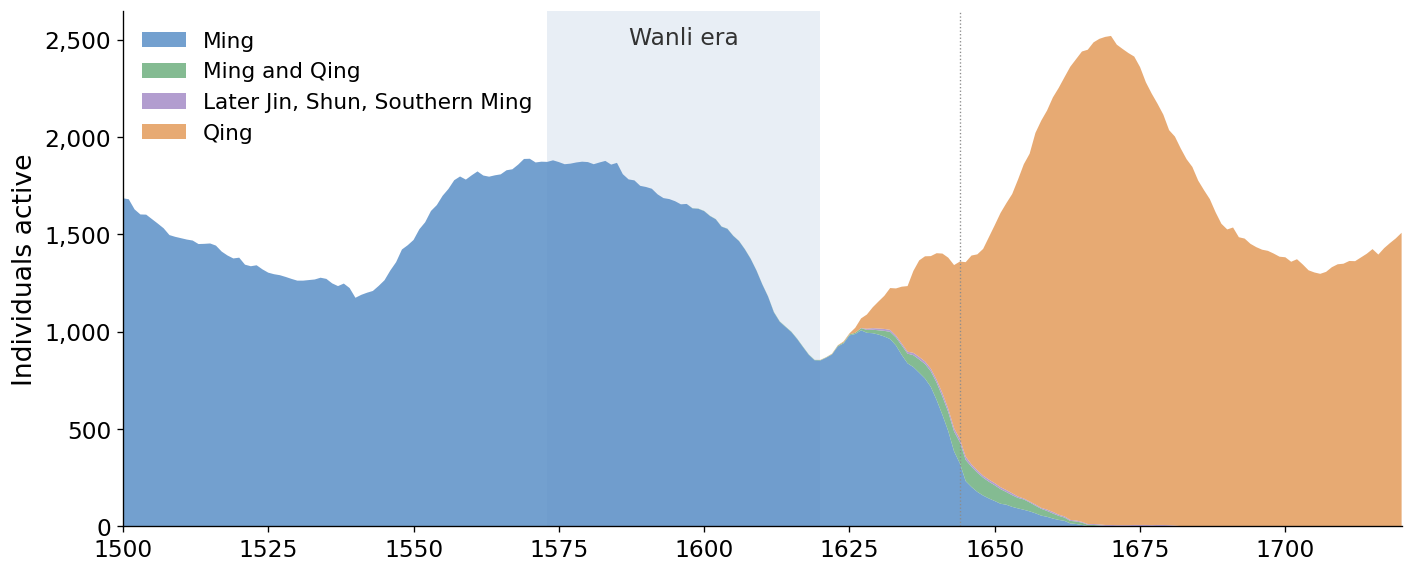

In [14]:
fig, ax = plt.subplots(figsize=FIGSIZE)
groups = territory_per_year.columns[1:]
ax.stackplot(territory_per_year['year'], *[territory_per_year[group] for group in groups],
             labels=groups, colors=[POLITY_GROUP_COLORS[group] for group in groups], alpha=0.85)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.axvline(ming_end, **REFERENCE_LINE)
ax.text((WANLI_START + WANLI_END) / 2, ax.get_ylim()[1] * 0.97, 'Wanli era', ha='center', va='top', color=TEXT)
ax.set_xlim(TERRITORY_START, TERRITORY_END)
ax.set_ylabel('Individuals active')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Figure 2: Births per decade on the territory, by source
Individuals whose Wikidata description is a CBDB identifier, versus all others.

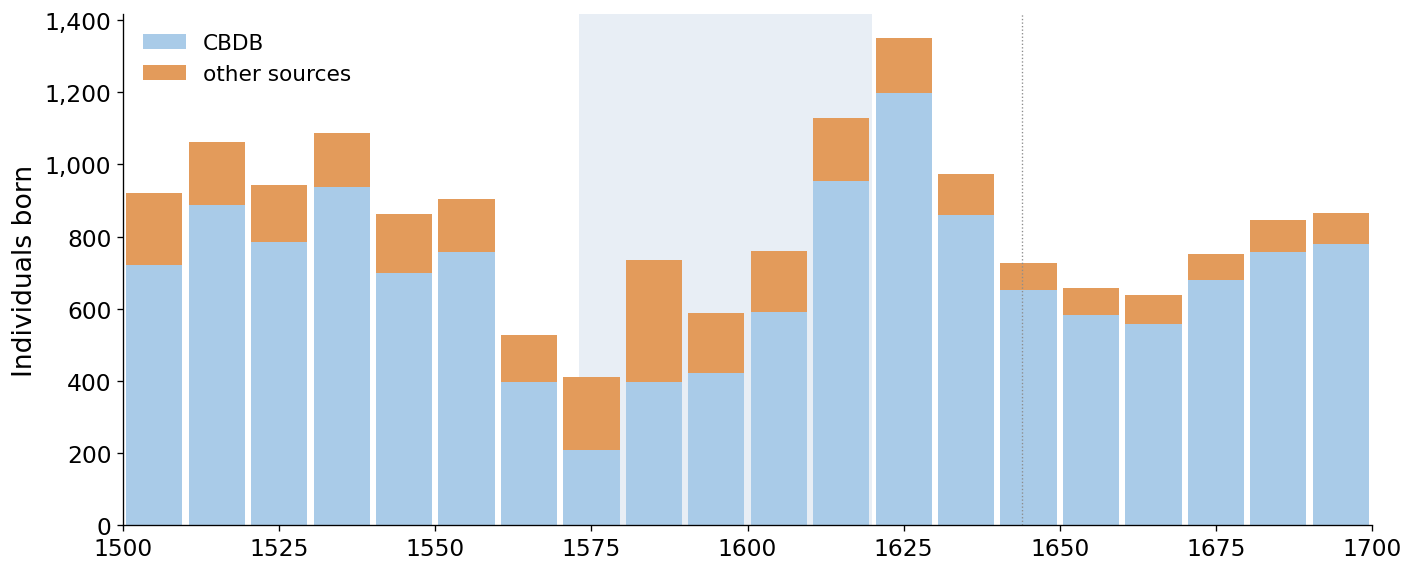

In [15]:
fig, ax = plt.subplots(figsize=FIGSIZE)
bottom = np.zeros(births_per_decade.height)
for source, color in SOURCE_COLORS.items():
    ax.bar(births_per_decade['decade'] + 5, births_per_decade[source], width=9, bottom=bottom, color=color, label=source)
    bottom += births_per_decade[source].to_numpy()
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.axvline(ming_end, **REFERENCE_LINE)
ax.set_xlim(*BIRTH_DECADES)
ax.set_ylabel('Individuals born')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Figure 3: When active lives start, by polity
First year of the active life, per polity group (5-year bins). Qing individuals whose active life starts left of the dotted line were active under the Ming but are counted only as Qing.

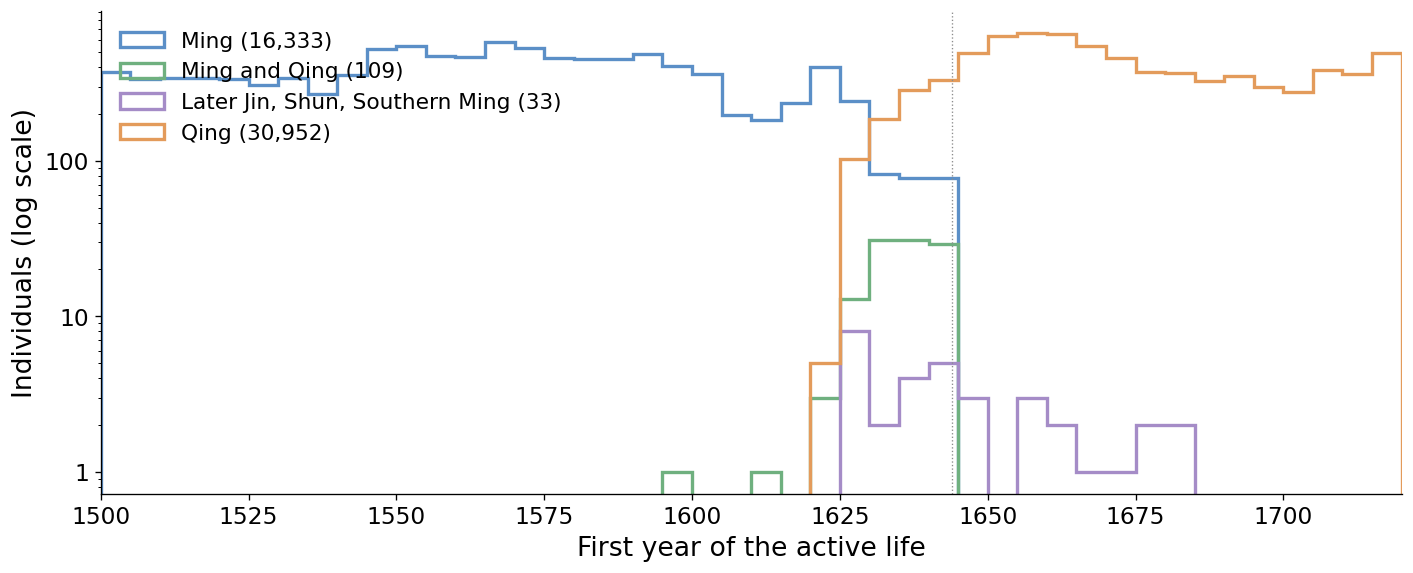

In [16]:
bins = np.arange(TERRITORY_START, TERRITORY_END + 5, 5)
fig, ax = plt.subplots(figsize=FIGSIZE)
for group in POLITY_GROUP_ORDER:
    starts = territory_people.filter(pl.col('polity_group') == group)['active_start']
    if starts.len():
        ax.hist(starts, bins=bins, histtype='step', lw=2, color=POLITY_GROUP_COLORS[group], label=f'{group} ({starts.len():,})')
ax.axvline(ming_end, **REFERENCE_LINE)
ax.set_xlim(TERRITORY_START, TERRITORY_END)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylabel('Individuals (log scale)')
ax.set_xlabel('First year of the active life')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Figure 4: Life paths across the fall of the Ming
The 12 most common paths (pre-active → active → post-active life) of individuals born before and dead after the end of the Ming.

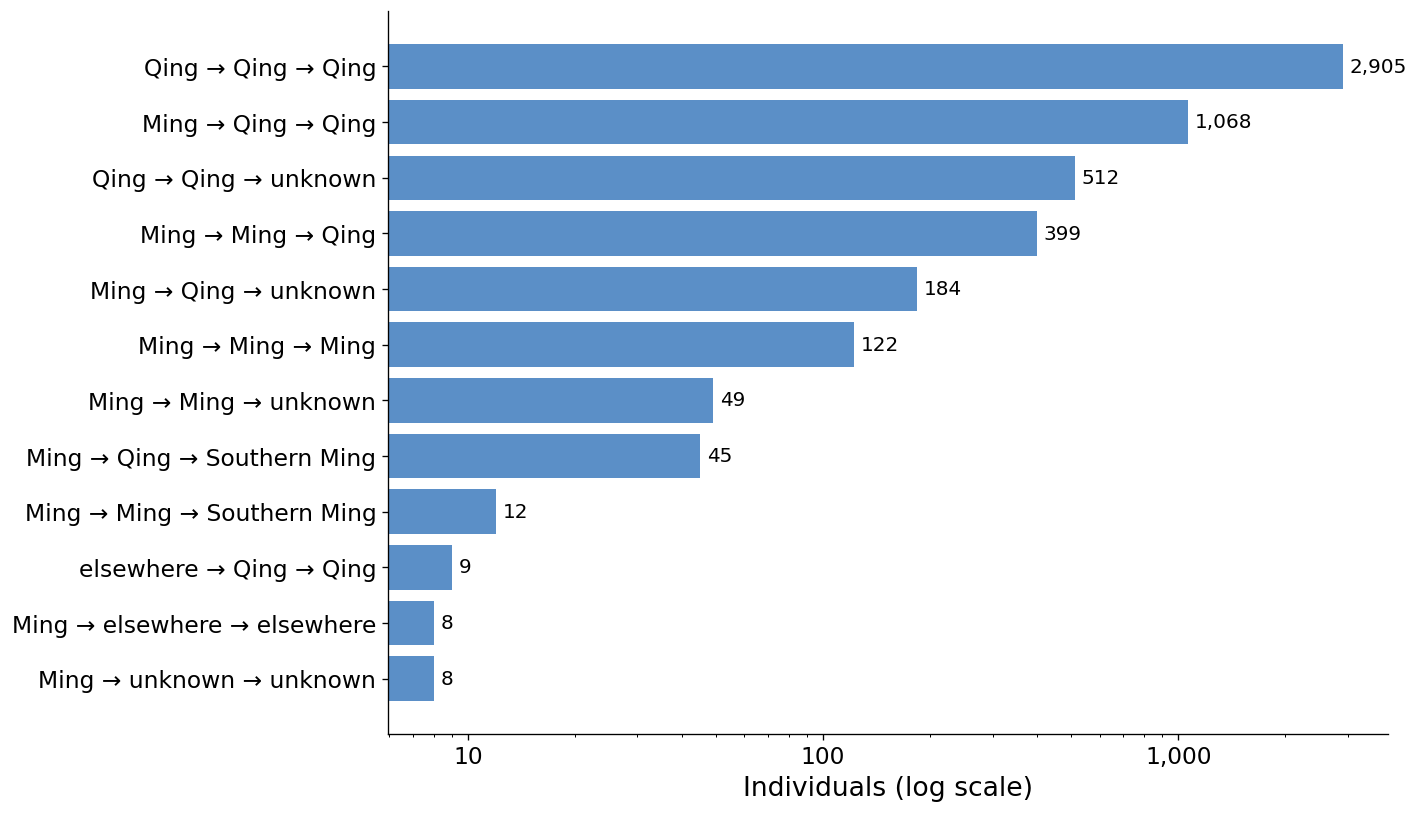

In [17]:
top_paths = life_paths.head(TOP_PATHS).sort('len')
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(top_paths['path'], top_paths['len'], color=MAIN_COLOR)
ax.bar_label(bars, labels=[f'{value:,}' for value in top_paths['len']], padding=4, fontsize=VALUE_LABEL_FONTSIZE)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Individuals (log scale)')
plt.tight_layout()
plt.show()

### Figure 5: Who was active during the Wanli era, beyond officials
Individuals with a main occupation other than "politician" (officials and individuals without occupation are left out, see the overview). Only active lives overlapping 1573–1620 are kept, so the curve rises and falls at the edges by construction.

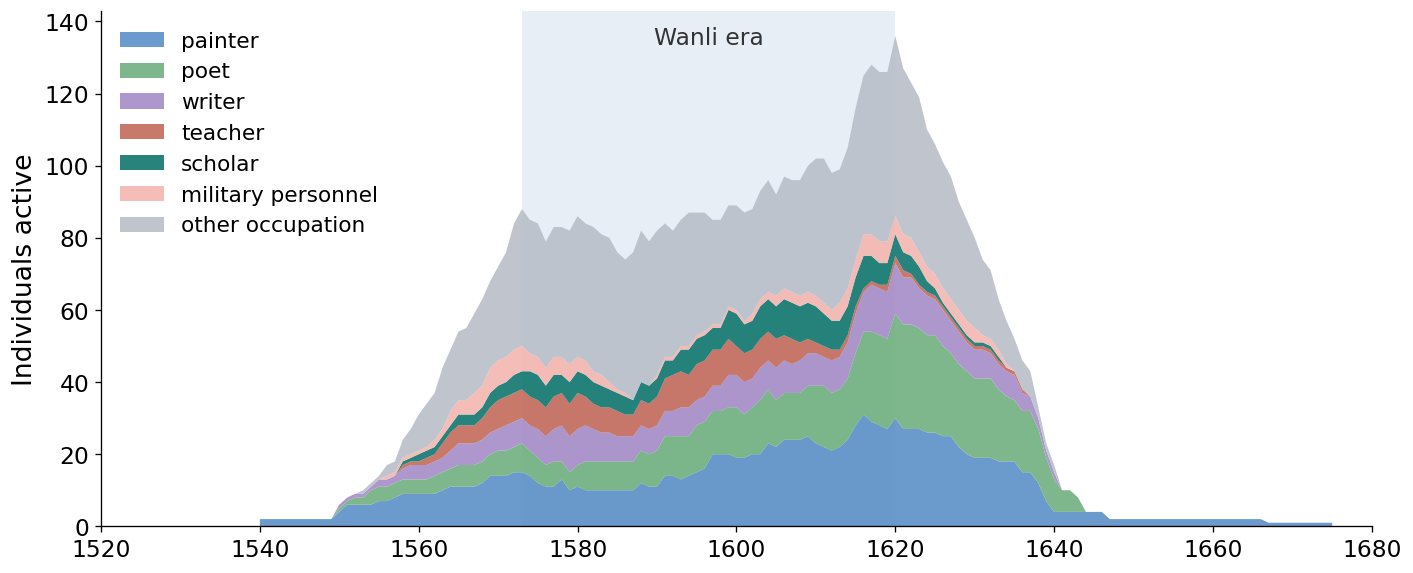

In [18]:
fig, ax = plt.subplots(figsize=FIGSIZE)
groups = active_per_year.columns[1:]
ax.stackplot(active_per_year['year'], *[active_per_year[group] for group in groups],
             labels=groups, colors=[GROUP_COLORS[group] for group in groups], alpha=0.9)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.text((WANLI_START + WANLI_END) / 2, ax.get_ylim()[1] * 0.97, 'Wanli era', ha='center', va='top', color=TEXT)
ax.set_xlim(SERIES_START, SERIES_END)
ax.set_ylabel('Individuals active')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.legend(loc='upper left', fontsize=13)
plt.tight_layout()
plt.show()

### Figure 6: Most common Wikidata occupations
All occupations of each individual of the Wanli set are counted.

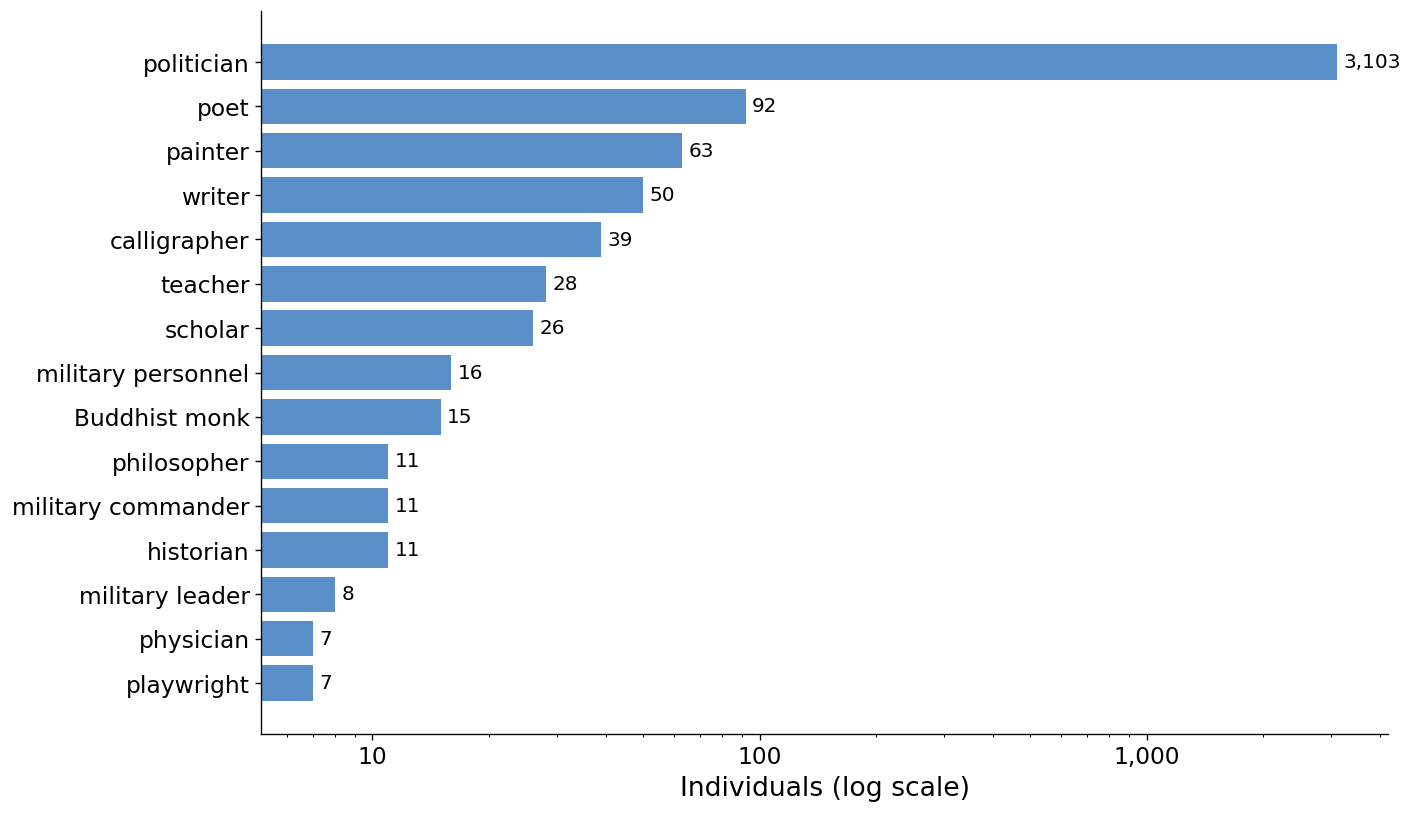

In [19]:
top_occupations = (
    occupations.group_by('occupation').agg(pl.col('qid').n_unique().alias('individuals'))
    .sort('individuals', descending=True).head(TOP_OCCUPATIONS)
    .sort('individuals')
)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(top_occupations['occupation'], top_occupations['individuals'], color=MAIN_COLOR)
ax.bar_label(bars, labels=[f'{value:,}' for value in top_occupations['individuals']], padding=4, fontsize=VALUE_LABEL_FONTSIZE)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Individuals (log scale)')
plt.tight_layout()
plt.show()

### Figure 7: The 40 most-linked individuals of the Wanli era
Ranked by number of Wikimedia sitelinks (Wikipedia editions and sister projects), shown in brackets. Thin grey line: life (birth to death); thick bar: active life; colour and right-hand label: main occupation.

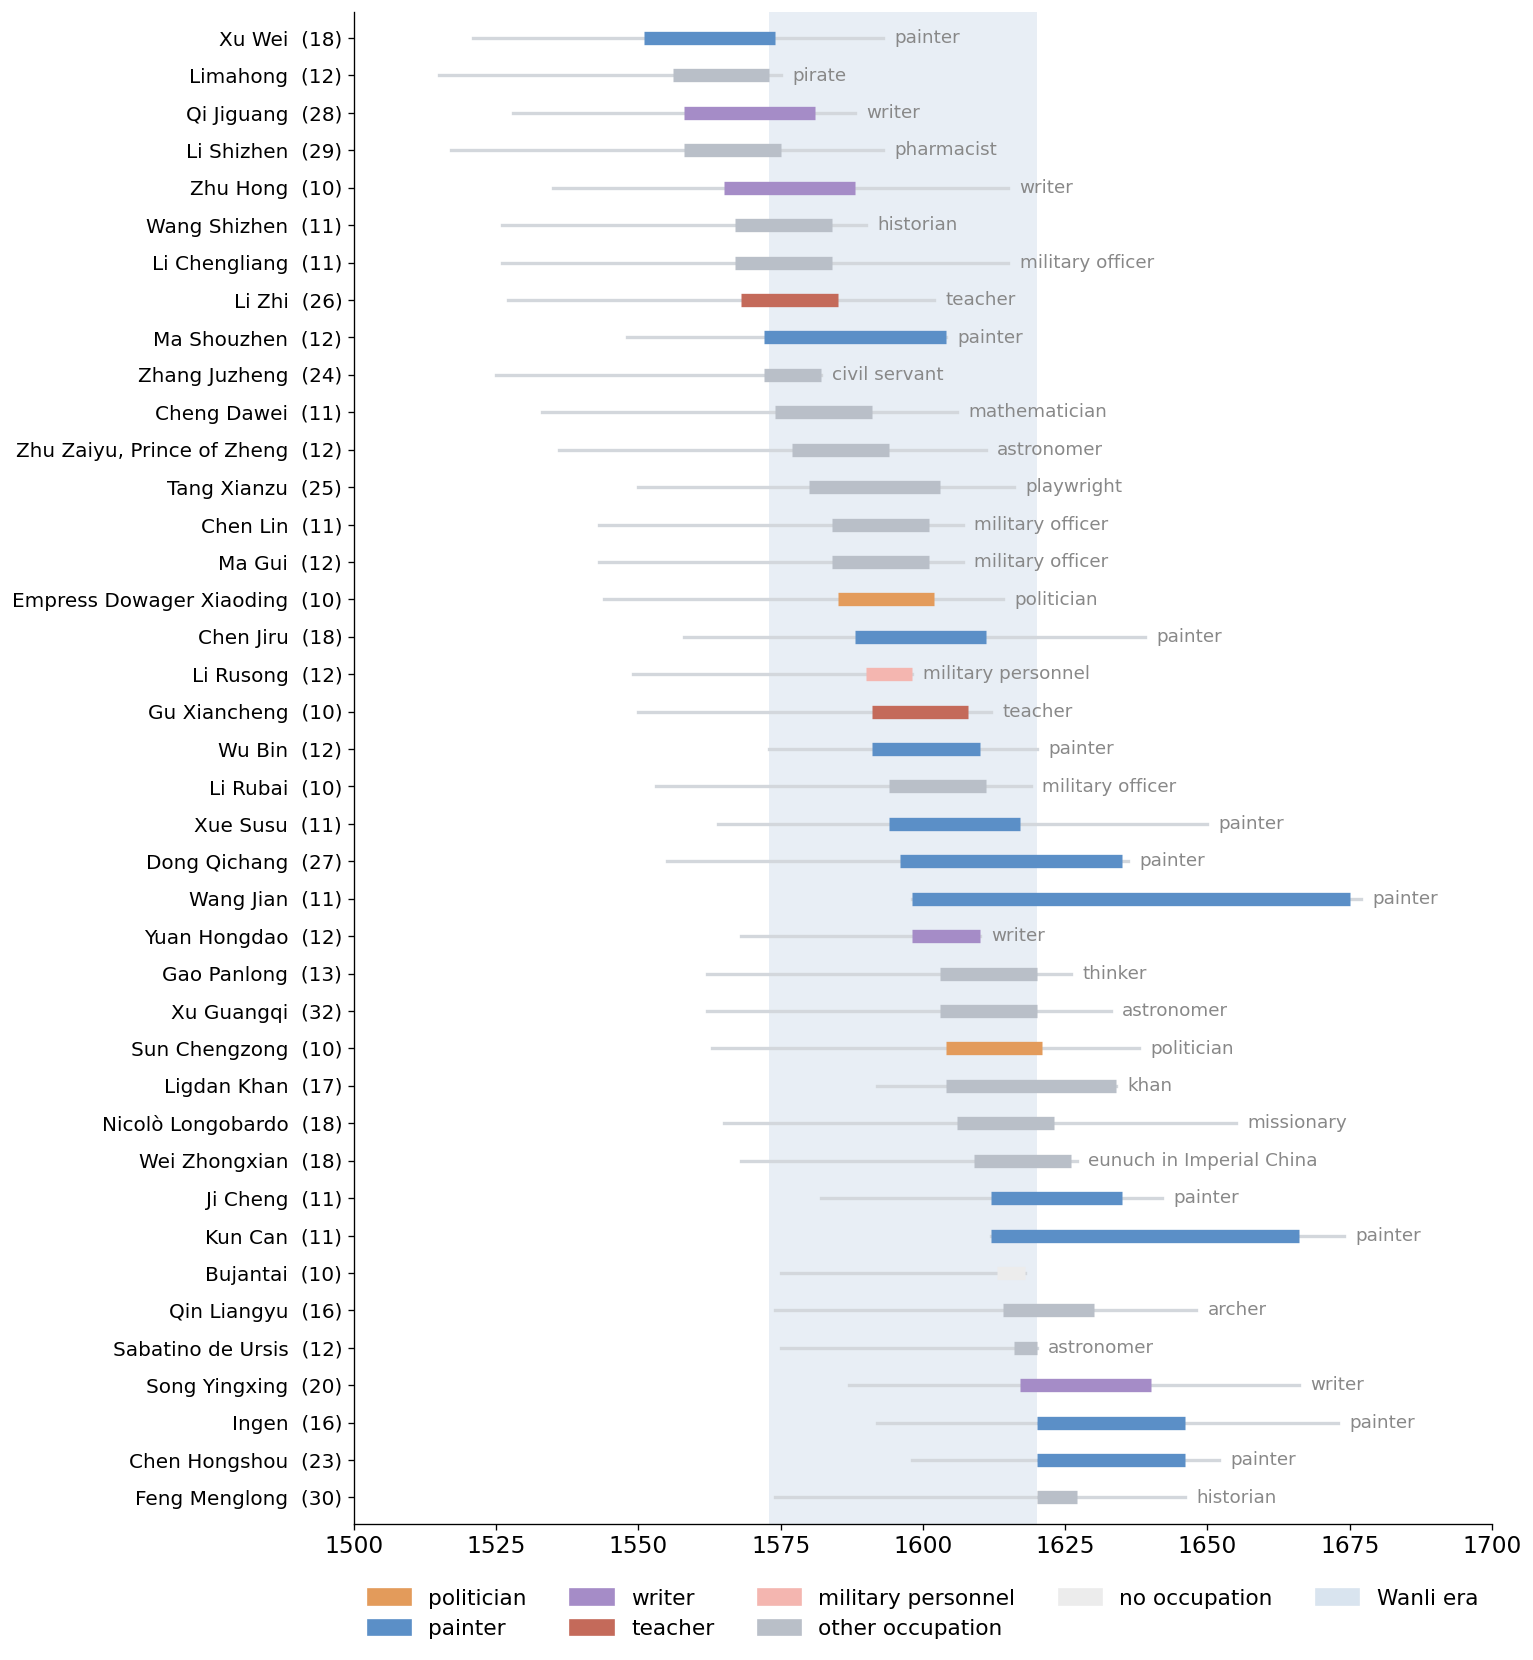

In [20]:
timeline = people.sort('sitelinks', descending=True).head(TOP_TIMELINE).sort('active_start', descending=True)

fig, ax = plt.subplots(figsize=(13, 14))
for position, person in enumerate(timeline.iter_rows(named=True)):
    if person['birth_year'] is not None and person['death_year'] is not None:
        ax.plot([person['birth_year'], person['death_year']], [position, position], color=LIGHT_GREY, lw=2, zorder=1)
    ax.plot([person['active_start'], person['active_end']], [position, position],
            color=GROUP_COLORS[person['group']], lw=8, solid_capstyle='butt', zorder=2)
    ax.text(max(person['active_end'], person['death_year'] or 0) + 2, position, person['main_occupation'] or '',
            va='center', fontsize=POINT_LABEL_FONTSIZE, color=MUTED_TEXT)
ax.axvspan(WANLI_START, WANLI_END, zorder=0, **WANLI_SHADE)
ax.set_yticks(range(timeline.height))
ax.set_yticklabels([f"{name}  ({links})" for name, links in zip(timeline['name'], timeline['sitelinks'])], fontsize=LONG_TICK_LABEL_FONTSIZE)
ax.set_ylim(-0.7, timeline.height - 0.3)
ax.set_xlim(1500, 1700)
present = [group for group in GROUP_ORDER if group in set(timeline['group'])]
ax.legend(handles=[Patch(color=GROUP_COLORS[group], label=group) for group in present] + [Patch(color=PALE_BLUE, label='Wanli era')],
          loc='upper center', bbox_to_anchor=(0.5, -0.03), ncol=5)
plt.tight_layout()
plt.show()

### Figure 8: Birthplaces of the Wanli set
Only individuals whose birthplace has coordinates (see the overview). Shaded: Ming territory around 1600 (Cliopatria).

215 of 5,285 individuals located


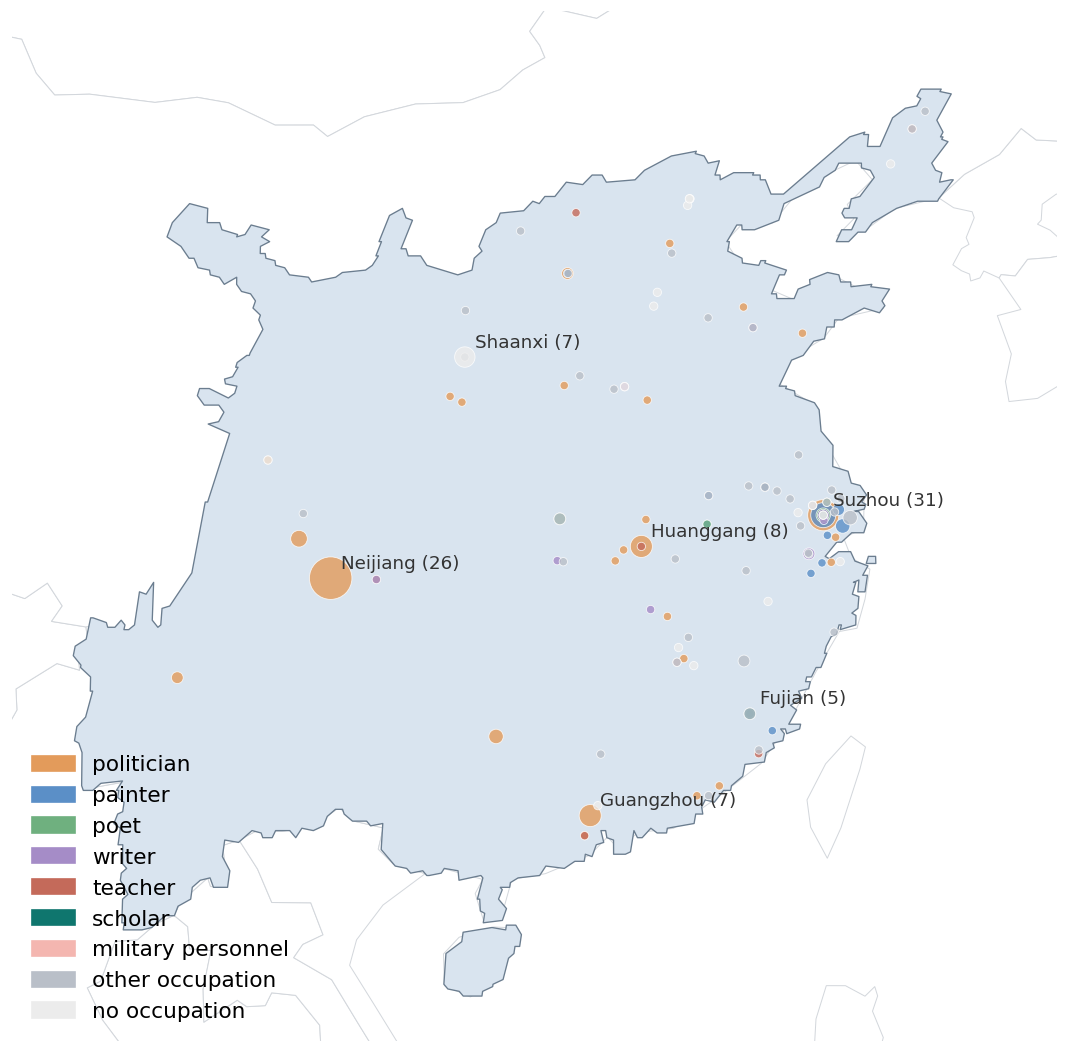

In [21]:
located = people.filter(pl.col('latitude').is_not_null())
birthplace_counts = located.group_by('birthplace', 'latitude', 'longitude', 'group').len()
countries = gpd.read_file(COUNTRIES_PATH)

fig, ax = plt.subplots(figsize=(10, 9))
countries.plot(ax=ax, color='white', edgecolor=LIGHT_GREY, lw=0.6)
gpd.GeoSeries([ming_1600], crs='EPSG:4326').plot(ax=ax, color=PALE_BLUE, edgecolor=SLATE, lw=0.8)
for group in GROUP_ORDER:
    subset = birthplace_counts.filter(pl.col('group') == group)
    if subset.height:
        ax.scatter(subset['longitude'], subset['latitude'], s=subset['len'] * 25, color=GROUP_COLORS[group],
                   alpha=0.8, edgecolor='white', lw=0.5, zorder=3)
for place in located.group_by('birthplace', 'latitude', 'longitude').len().sort('len', descending=True).head(6).iter_rows(named=True):
    ax.annotate(f"{place['birthplace']} ({place['len']})", (place['longitude'], place['latitude']),
                xytext=(6, 6), textcoords='offset points', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
ax.set_xlim(*MAP_EXTENT[:2])
ax.set_ylim(*MAP_EXTENT[2:])
ax.set_axis_off()
present = [group for group in GROUP_ORDER if group in set(birthplace_counts['group'])]
ax.legend(handles=[Patch(color=GROUP_COLORS[group], label=group) for group in present], loc='lower left')
print(f'{located.height:,} of {people.height:,} individuals located')
plt.tight_layout()
plt.show()

## Biographies
### The 30 most-linked individuals of the Wanli era

In [22]:
def years(start, end):
    return f"{start if start is not None else '?'}–{end if end is not None else '?'}"


def biography_table(frame):
    return pd.DataFrame({
        'name': [f"{name} {original or ''}".strip() for name, original in zip(frame['name'], frame['name_original'])],
        'life': [years(birth, death) for birth, death in zip(frame['birth_year'], frame['death_year'])],
        'active life': [years(start, end) for start, end in zip(frame['active_start'], frame['active_end'])],
        'occupations': frame['occupations'].fill_null('').to_list(),
        'description': frame['description'].fill_null('').to_list(),
        'birthplace': frame['birthplace'].fill_null('').to_list(),
        'polities': frame['polities'].to_list(),
        'sitelinks': frame['sitelinks'].to_list(),
    })


pd.set_option('display.max_colwidth', 90)
biography_table(people.sort('sitelinks', descending=True).head(TOP_BIOGRAPHIES)).style.hide(axis='index')

name,life,active life,occupations,description,birthplace,polities,sitelinks
Xu Guangqi,1562–1633,1603–1620,"astronomer, mathematician, translator, writer, politician","late-Ming-dynasty Chinese politician, Scholar, Lay Catholic leader and Servant of God (*1562 – †1633)",Shanghai,Ming Dynasty,32
Feng Menglong,1574–1646,1620–1627,"historian, collector of fairy tales, writer, poet",Chinese writer and poet,Suzhou,Ming Dynasty,30
Li Shizhen,1517–1593,1558–1575,"pharmacist, naturalist, botanist, writer, physician",Chinese polymath and scientist (1517-1593),Qizhou,Ming Dynasty,29
Qi Jiguang,1528–1588,1558–1581,"writer, military personnel",Ming Dynasty general,Shandong,Ming Dynasty,28
Dong Qichang,1555–1636,1596–1635,"painter, art theorist, art historian, calligrapher, writer, poet, politician","Chinese painter, scholar, calligrapher, and art theorist (1555-1636)",Songjiang,Ming Dynasty,27
Li Zhi,1527–1602,1568–1585,"teacher, philosopher",Chinese philosopher (1527–1602),Jinjiang,Ming Dynasty,26
Tang Xianzu,1550–1616,1580–1603,"playwright, writer, poet",Chinese playwright (1550-1616),Linchuan District,Ming Dynasty,25
Zhang Juzheng,1525–1582,1572–1582,"civil servant, writer, statesperson, politician",Chinese Grand Secretary (1525-1582),Jiangling County,Ming Dynasty,24
Chen Hongshou,1598–1652,1620–1646,"painter, graphic artist, calligrapher, writer",Chinese artist (1598-1652),Zhuji,Qing Dynasty,23
Song Yingxing,1587–1666,1617–1640,writer,Chinese scholar (1587-1666),Fengxin County,Ming Dynasty,20


### Top 5 per main occupation

In [23]:
for group in GROUP_ORDER:
    subset = people.filter(pl.col('group') == group).sort('sitelinks', descending=True).head(5)
    print(f'{group}: {people.filter(pl.col("group") == group).height:,} individuals')
    display(biography_table(subset).style.hide(axis='index'))

politician: 3,034 individuals


name,life,active life,occupations,description,birthplace,polities,sitelinks
Sun Chengzong,1563–1638,1604–1621,politician,Grand Secretary of the late Ming Dynasty,Gaoyang County,Ming Dynasty,10
Empress Dowager Xiaoding,1544–1614,1585–1602,politician,mother of the Wanli Emperor; CBDB ID=67555,,Ming Dynasty,10
Shen Shixing,1535–1614,1576–1593,politician,Ming dynasty person CBDB=123973 (1535–1614),Suzhou,Ming Dynasty,9
Cuyen,1580–1615,1615–1615,politician,Manchu prince (1580-1615),,Ming Dynasty,9
Shen Yiguan,1531–1617,1572–1589,politician,Ming dynasty person CBDB = 124055,,Ming Dynasty,7


painter: 63 individuals


name,life,active life,occupations,description,birthplace,polities,sitelinks
Dong Qichang,1555–1636,1596–1635,"painter, art theorist, art historian, calligrapher, writer, poet, politician","Chinese painter, scholar, calligrapher, and art theorist (1555-1636)",Songjiang,Ming Dynasty,27
Chen Hongshou,1598–1652,1620–1646,"painter, graphic artist, calligrapher, writer",Chinese artist (1598-1652),Zhuji,Qing Dynasty,23
Chen Jiru,1558–1639,1588–1611,"painter, autobiographer, calligrapher, writer, poet",Chinese artist (1558-1639),Songjiang,Ming Dynasty,18
Xu Wei,1521–1593,1551–1574,"painter, playwright, calligrapher, writer, poet, literary scholar, strategist",Ming Dynasty painter (1521-1593),Shaoxing,Ming Dynasty,18
Ingen,1592–1673,1620–1646,"painter, calligrapher, poet, Buddhist monk",Buddhist monk (1592-1673),Fuqing,Ming Dynasty,16


poet: 52 individuals


name,life,active life,occupations,description,birthplace,polities,sitelinks
Lü Tiancheng,1580–1618,1610–1618,poet,,,Ming Dynasty,6
Zhong Xing,1574–1625,1604–1625,"poet, politician",Ming dynasty politician,Hubei,Ming Dynasty,6
Yuan Zhongdao,1570–1624,1600–1623,"poet, politician",Chinese poet (1570-1624),Hubei,Ming Dynasty,5
Xia Yunyi,1585–1645,1615–1638,"poet, politician",Ming dynasty politician (1596–1645),,Ming Dynasty,5
Shisheng Tang,1551–1636,1581–1604,poet,Ming dynasty person CBDB = 129447,,Ming Dynasty,2


... (8 outputs left out)

other occupation: 134 individuals


name,life,active life,occupations,description,birthplace,polities,sitelinks
Xu Guangqi,1562–1633,1603–1620,"astronomer, mathematician, translator, writer, politician","late-Ming-dynasty Chinese politician, Scholar, Lay Catholic leader and Servant of God (*1562 – †1633)",Shanghai,Ming Dynasty,32
Feng Menglong,1574–1646,1620–1627,"historian, collector of fairy tales, writer, poet",Chinese writer and poet,Suzhou,Ming Dynasty,30
Li Shizhen,1517–1593,1558–1575,"pharmacist, naturalist, botanist, writer, physician",Chinese polymath and scientist (1517-1593),Qizhou,Ming Dynasty,29
Tang Xianzu,1550–1616,1580–1603,"playwright, writer, poet",Chinese playwright (1550-1616),Linchuan District,Ming Dynasty,25
Zhang Juzheng,1525–1582,1572–1582,"civil servant, writer, statesperson, politician",Chinese Grand Secretary (1525-1582),Jiangling County,Ming Dynasty,24


no occupation: 1,910 individuals


name,life,active life,occupations,description,birthplace,polities,sitelinks
Bujantai,1575–1618,1613–1618,,Jurchen chieftain,,Ming Dynasty,10
Empress Xiaoan,1536–1596,1574–1593,,Ming Dynasty empress,,Ming Dynasty,9
Šurhaci,1564–1611,1602–1611,,Jurchen leader,Ming dynasty,Ming Dynasty,9
Empress Xiaoduanxian,1565–1620,1603–1620,,Ming Dynasty empress,Yuyao City,Ming Dynasty,9
Taksi,1543–1582,1581–1582,,Jurchen chieftain and father of Nurhaci,,Ming Dynasty,8


### Women of the era

In [24]:
women = people.filter(pl.col('is_female')).sort('sitelinks', descending=True)
print(f'{women.height} women')
biography_table(women).style.hide(axis='index')

47 women


name,life,active life,occupations,description,birthplace,polities,sitelinks
Qin Liangyu,1574–1648,1614–1630,archer,Chinese female general in Ming dynasty,,Ming Dynasty,16
Ma Shouzhen,1548–1604,1572–1604,"painter, changji, composer, poet","Chinese courtesan, painter, poet, and composer (1548-1604)",Nanjing,Ming Dynasty,12
Xue Susu,1564–1650,1594–1617,"painter, embroiderer, changji, poet","Chinese prostitute, poet, artist, mounted archer, and Buddhist nun (c. 1564-1650)",Suzhou,Ming Dynasty,11
Empress Dowager Xiaoding,1544–1614,1585–1602,politician,mother of the Wanli Emperor; CBDB ID=67555,,Ming Dynasty,10
Empress Xiaoan,1536–1596,1574–1593,,Ming Dynasty empress,,Ming Dynasty,9
Empress Xiaoduanxian,1565–1620,1603–1620,,Ming Dynasty empress,Yuyao City,Ming Dynasty,9
Qiu Zhu,1525–1585,1555–1578,painter,Chinese Ming Dynasty painter (fl. 1565–1585),Taicang,Ming Dynasty,9
Empress Xiaocigao,1575–1603,1603–1603,,empress of the Qing dynasty,,Ming Dynasty,8
Noble Consort Zheng,1565–1630,1603–1622,,Wanli Emperor's concubine,Daxing District,Ming Dynasty,8
Lin Xue,1582–1642,1612–1635,painter,Chinese painter,Fujian,Ming Dynasty,7


### A random sample of the long tail
Most individuals come from the China Biographical Database (CBDB): no sitelink and a description that is only an identifier.

In [25]:
long_tail = people.filter(pl.col('sitelinks') == 0).sample(10, seed=SEED)
biography_table(long_tail).style.hide(axis='index')

name,life,active life,occupations,description,birthplace,polities,sitelinks
Wan Zhonglu,1541–1600,1579–1598,,Ming dynasty person CBDB = 205555,,Ming Dynasty,0
Feng Yixiang,1536–1595,1574–1593,,Ming dynasty person CBDB = 205342,,Ming Dynasty,0
Zhang Yi,1516–1575,1554–1573,,Ming dynasty person CBDB = 203988,,Ming Dynasty,0
Xue Donghai,1529–1588,1567–1586,,Ming dynasty person CBDB = 205044,,Ming Dynasty,0
Xiong Wei,1533–1592,1571–1590,,Ming dynasty person CBDB = 205287,,Ming Dynasty,0
Lin Qidi,1528–1587,1566–1585,,Ming dynasty person CBDB = 204737,,Ming Dynasty,0
Wan Huafu,1571–1630,1609–1628,,Ming dynasty person CBDB = 131923,,Ming Dynasty,0
Cui Dong,1525–1584,1563–1582,,Ming dynasty person CBDB = 204780,,Ming Dynasty,0
Ren Ruliang,1531–1590,1569–1588,,Ming dynasty person CBDB = 205177,,Ming Dynasty,0
Zhang Shiyou,1555–1614,1593–1612,,Ming dynasty person CBDB = 207066,,Ming Dynasty,0


## Check: who are these individuals?
### Where the dates come from

In [26]:
date_sources = (
    people
    .with_columns(
        pl.col('birth_source').fill_null('missing'),
        pl.col('death_source').fill_null('missing'),
        (pl.col('active_end') - pl.col('active_start')).alias('active_span'),
    )
    .group_by('birth_source', 'death_source')
    .agg(pl.len().alias('individuals'), pl.col('active_span').median().alias('median_active_span'))
    .with_columns((pl.col('individuals') / people.height * 100).round(1).alias('share_%'))
    .sort('individuals', descending=True)
)
assert date_sources['individuals'].sum() == people.height
date_sources

birth_source,death_source,individuals,median_active_span,share_%
str,str,u32,f64,f64
"""wikidata""","""estimated""",3974,17.0,75.2
"""wikidata""","""wikidata""",1000,17.0,18.9
"""estimated""","""wikidata""",311,19.0,5.9


In [27]:
print('Most common active-life lengths (years):')
people.select((pl.col('active_end') - pl.col('active_start')).alias('active_span'))['active_span'].value_counts(sort=True).head(5)

Most common active-life lengths (years):


active_span,count
i64,u32
17,3059
19,1830
23,140
0,31
16,27


### Why does the number of active people fall after the Wanli era?

**1. The fall is real on the whole territory, and it comes from a smaller birth cohort.** Counting everyone active in the territory, whatever the polity, gives about 1,870 people in 1573, 1,620 in 1600 and 855 in 1620. The count then climbs back to 1,360 in 1644 and about 2,500 around 1670 (Figure 1). Active lives are estimated as birth + about 40 to birth + about 60 years, so the people active in 1600–1620 are those born in 1550–1580. Figure 2 shows that this cohort is small: 528 births in the 1560s and 410 in the 1570s, against about 900 per decade before. The dip is almost entirely in the CBDB records (397 and 210 births), while the other sources stay stable. So the dip reflects which CBDB records made it into Wikidata with a birth year, not a demographic event.

**2. After 1620 the next generations are matched to the Qing, not lost.** People born from about 1590 have their active life around and after 1644, and most of them are matched to the Qing (Figure 1, orange). Only 109 have both Ming and Qing in their active life, and 33 a transition regime (Later Jin, Shun, Southern Ming). So the Ming curve falls to zero after 1644 by construction, while the territory as a whole recovers.

**3. Most individuals carry only one dynasty, because the polity mostly comes from Wikidata citizenship.** Of the 5,376 individuals born before and dead after 1644 (Figure 4):
- **2,905 are "Qing" in every stage.** Their only Wikidata location is "country of citizenship: Qing dynasty", and Cliopatria's Qing starts in 1645. So their years before 1645 have no polity, even though they were born and grew up under the Ming.
- **1,068 are Ming → Qing → Qing** and **399 are Ming → Ming → Qing**. These are the people seen crossing the change of dynasty.
- **122 stay Ming throughout,** and **57 end under the Southern Ming.**

Figure 3 shows the same thing from another angle: 838 "Qing" individuals start their active life before 1644. They were active under the Ming but are counted as Qing.

### Who they are

**Mostly officials from the CBDB.** About 5,300 individuals were active in the territory under the Wanli Emperor. Most come from the China Biographical Database (CBDB). In Wikidata they are almost always "politician", which means a degree-holder or civil official. Four in five have only a CBDB identifier as their description, and about a third have no Wikipedia or other Wikimedia page. About 1,900 have no occupation at all. For these people, Cultura records that they existed and when, but not what they did.

**A small, well-known elite.** Only about 120 individuals have five or more sitelinks, and they give the familiar picture of the late Ming:
- *Statesmen and the court:* the Grand Secretary Zhang Juzheng, whose reforms opened the reign, the Donglin academics Gu Xiancheng and Gao Panlong, and the eunuch Wei Zhongxian.
- *Science and learning:* Li Shizhen (pharmacology), Song Yingxing (technology), Zhu Zaiyu (music theory and mathematics), Xu Guangqi (astronomy and mathematics, a Catholic convert).
- *Letters and arts:* Tang Xianzu (theatre), Feng Menglong (vernacular stories), Yuan Hongdao (poetry), the painters Dong Qichang, Chen Jiru, Xu Wei, Wu Bin and Chen Hongshou, and the philosopher Li Zhi.
- *War:* the generals Qi Jiguang, Li Chengliang, Li Rusong and Qin Liangyu, and the pirate Limahong.

**The emperors are missing, because of a matching error.** The Wanli, Taichang, Tianqi and Chongzhen emperors, Nurhaci and Hong Taiji have "Chinese Empire" as their active-life location, taken from their office. The export matches this location by its single coordinate point, which falls inside a Cliopatria polygon named "Golden Horde" at this period. The same error affects 373 individuals in the whole database, mostly emperors of every dynasty (the Han emperors get the Xiongnu, the Song emperors Western Xia, and so on). The life-stage polity export should not match country- or empire-level items by their coordinate point.

**The edges of the empire.** The Jesuits Nicolò Longobardo and Sabatino de Ursis, the Mongol Ligdan Khan (through his deathplace) and the monk Ingen, who later founded the Ōbaku school in Japan, are matched to the Ming. Chen Hongshou is counted as Qing although his active life (1620–1646) is almost all Ming.

**Women are rare (47, under 1%).** They fall into two kinds. On one side, court women and famous artists: the courtesan-painters Ma Shouzhen and Xue Susu, the painter-poet Fang Weiyi, and the general Qin Liangyu. On the other, CBDB women poets known only as "wife of …".

**The dates are mostly estimated, which shapes the figures.** Three quarters of the individuals have a Wikidata birth year and an *estimated* death. Above all, 99.5% have an *estimated* active life, even when both dates are known: birth + a cohort median age (38 or 41) to birth + another (58 or 60). This is why most active lives last exactly 17 or 19 years. The curves therefore follow the birth dates, smoothed by a fixed window. They are not the real career lengths: Xu Guangqi's active life, for instance, ends in 1620 although he served until his death in 1633.